## Evaluation of high-order thermal response factors

In [4]:
from matplotlib import pyplot as plt
import numpy as np

import pygfunction3 as gt3

### Parameters of the borehole

In [16]:
# Dimensions of the borehole
L = 150.            # Length [m]
D = 4.              # Buried depth [m]
r_b = 0.075         # Radius [m]
p_head = [0., 0.]   # Head position [m]
borehole = gt3.borehole.Borehole(L, D, r_b, p_head)

# Number of nodes along the borehole
n_nodes = 11
basis = gt3.basis.Basis(n_nodes)

### Parameters for the evaluation of thermal response factors

In [17]:
# Ground thermal diffusivity
alpha = 1e-6        # [m2/s]

# Time values at which the temperature response is evaluated
n_times = 51
ln_tts = np.linspace(-5., 5., n_times)
time = L**2 / (9 * alpha) * np.exp(ln_tts)

### Reference solution

In [ ]:
h_ref = gt3.thermal_response_factors.thermal_response_factors_to_borehole(
    time,
    alpha,
    borehole,
    borehole,
    basis,
    r_min=r_b,
    backend='detailed',
    fls_backend='integral',
)

### Thermal response factors using the recurrence formula

In [19]:
h_rec = gt3.thermal_response_factors.thermal_response_factors_to_borehole(
    time,
    alpha,
    borehole,
    borehole,
    basis,
    r_min=r_b,
    backend='detailed',
    fls_backend='recurrence',
)

### Thermal response factors at the last time step
Evaluated at the top, middle, and bottom nodes.

In [ ]:
k = -1
center = n_nodes // 2
n = [0, center, n_nodes - 1]

Profile along the borehole length

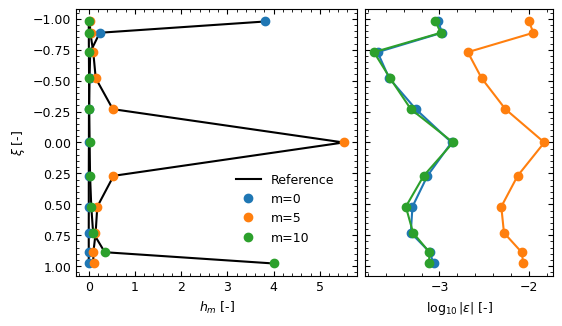

In [23]:
plt.rcParams.update({'font.size': 9})
fig, ax = plt.subplots(ncols=2, layout='constrained', sharey=True, width_ratios=[3, 2])
fig.set_size_inches(140. / 25.4, 80. / 25.4)
gt3.plot._format_axis(ax[0], axis_labels=[f'$h_m$ [-]', r'$\xi$ [-]'], inverse_y=True)
gt3.plot._format_axis(ax[1])

ax[1].set_xlabel(r'$\log_{10}|\varepsilon|$ [-]')
ax[0].plot(h_ref[k, :, n[0]], basis.xi, 'k-', label='Reference')

# Reference values
for _n in n[1:]:
    ax[0].plot(h_ref[k, :, _n], basis.xi, 'k-')

# Recurrence values and error
for _n in n:
    line = ax[0].plot(h_rec[k, :, _n], basis.xi, 'o', label=f'm={_n}')
    error = np.abs(h_rec[k, :, _n] - h_ref[k, :, _n])
    error[error == 0.] = np.nan
    ax[1].plot(np.log10(error), basis.xi, 'o-', color=line[0].get_color())

ax[0].legend(frameon=False, loc=(0.55, 0.1))
plt.show()
# fig.savefig('thermal_response_factor_accuracy.png', dpi=500)

Error at mid-depth

In [25]:
k = -1
m = 0
i = center
error = np.abs(h_rec[k, i, m] - h_ref[k, i, m])
print(f'Error for the last time step, node i={i} and order m={m}: {error:.2e}')

Error for the last time step, node i=5 and order m=0: 1.36e-03
